# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 **without ImageNet pretraining and without tuning** (`NO_TUNING_ARCH_HYPERPARAMS["resnet18"]`), then saves its results and weights to disk for the results notebook. This is the baseline role AlexNet used to play — see `wwtw_utils.py`'s `ARCH_HYPERPARAMS` comment for why the baseline is now the *same* architecture as the tuned, pretrained `resnet18` run rather than a different one.


In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: off
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = NO_TUNING_ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (ResNet-18, trained from scratch)

In [3]:
# ---------------------------------------------------------
# Define the CNN (ResNet-18, trained from scratch — no ImageNet weights)
# ---------------------------------------------------------
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18 (scratch)] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.0133 acc 0.503 | val loss 0.9432 acc 0.563 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 0.8077 acc 0.600 | val loss 0.7623 acc 0.610 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.7696 acc 0.611 | val loss 0.8273 acc 0.613


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.6806 acc 0.632 | val loss 0.6961 acc 0.672 *


...

[ResNet-18 (scratch)] Epoch  14/100 | LR: 1.00e-04 | train loss 0.2200 acc 0.901 | val loss 0.6051 acc 0.749


[ResNet-18 (scratch)] Epoch  15/100 | LR: 1.00e-05 | train loss 0.1634 acc 0.915 | val loss 0.9704 acc 0.749


[ResNet-18 (scratch)] Epoch  16/100 | LR: 1.00e-05 | train loss 0.1322 acc 0.938 | val loss 0.8101 acc 0.734


[ResNet-18 (scratch)] Epoch  17/100 | LR: 1.00e-05 | train loss 0.0709 acc 0.965 | val loss 0.8175 acc 0.734


[ResNet-18 (scratch)] Epoch  18/100 | LR: 1.00e-05 | train loss 0.0666 acc 0.964 | val loss 0.7179 acc 0.749

[ResNet-18 (scratch)] No val loss improvement for 10 epochs — stopping early at epoch 18.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.6034)


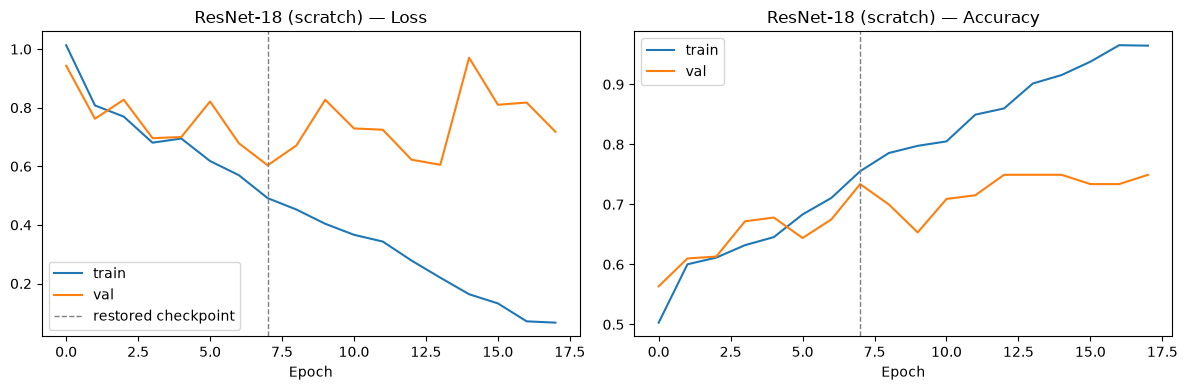

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.655


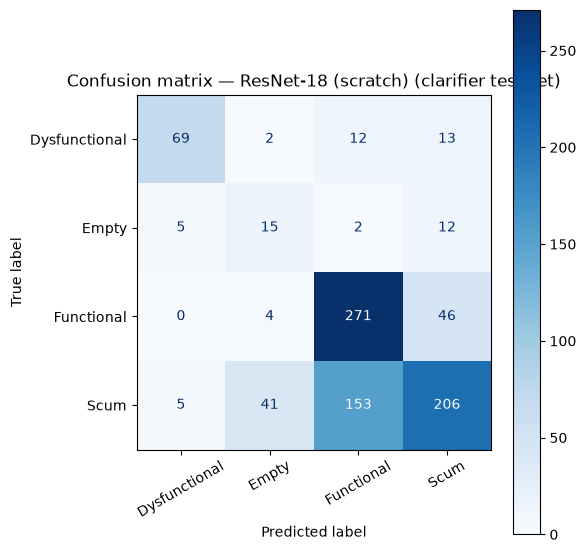

               precision    recall  f1-score   support

Dysfunctional      0.873     0.719     0.789        96
        Empty      0.242     0.441     0.312        34
   Functional      0.619     0.844     0.714       321
         Scum      0.744     0.509     0.604       405

     accuracy                          0.655       856
    macro avg      0.619     0.628     0.605       856
 weighted avg      0.691     0.655     0.654       856



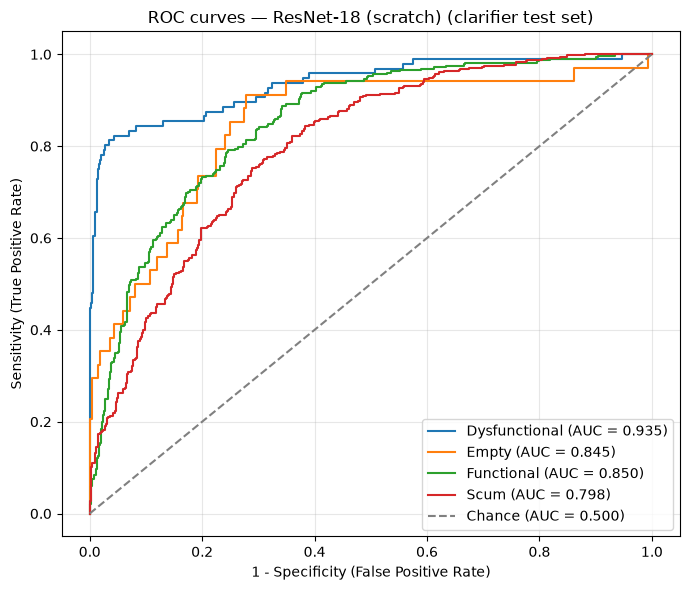

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.935
  Empty          : 0.845
  Functional     : 0.850
  Scum           : 0.798

Mean AUC (over 4/4 classes with test examples): 0.857


(np.float64(0.655373831775701),
 {'Dysfunctional': 0.9352521929824562,
  'Empty': 0.8451409760984686,
  'Functional': 0.8495414446676566,
  'Scum': 0.7980838192220306})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_noaug/results_clarifier_resnet18_scratch_chronological.pkl


Saved model weights to ../models/pad/clarifier_resnet18_scratch_cnn.pt
